[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_metcalfe_rolling/BA_L2_metcalfe_rolling.ipynb)

# BA_L2_metcalfe_rolling: A Rolling Metcalfe Elasticity

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The elasticity of Bitcoin market value to transactions per day estimated on rolling 36-month windows of monthly means, November 2014 to October 2025, with Newey-West 95% intervals, against the Metcalfe value b = 2.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['statsmodels']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

The regression $\ln M_t = a + b \ln n_t + u_t$ ($M_t$: Bitcoin market value; $n_t$: transactions per day; monthly
means with the 11 days of recording error removed) is estimated on every window of 36 consecutive months. The 95%
interval is $\hat b \pm 1.96\,\mathrm{SE}$ with Newey–West standard errors (6 lags). Metcalfe's law predicts $b = 2$.

**How to read the chart.** Each point is dated at the last month of its window. A stable network-value elasticity
would keep the band around one level; intervals that miss 2 in most windows reject Metcalfe's law locally.

In [6]:
import statsmodels.api as sm

tx_btc = pd.to_numeric(onchain('transaction')['BTC'], errors='coerce')
mc_btc = pd.to_numeric(onchain('Mktcap')['BTC'], errors='coerce')
mc_btc.loc['2023-08-27':'2023-09-06'] = np.nan                     # recording error (Lecture 1)
mm = pd.DataFrame({'tx': tx_btc, 'mc': mc_btc}).dropna().resample('ME').mean().dropna()
y, x = np.log(mm['mc']), np.log(mm['tx'])
print(f'Monthly means: {len(mm)} months, {mm.index[0]:%B %Y} to {mm.index[-1]:%B %Y}')

Monthly means: 132 months, November 2014 to October 2025


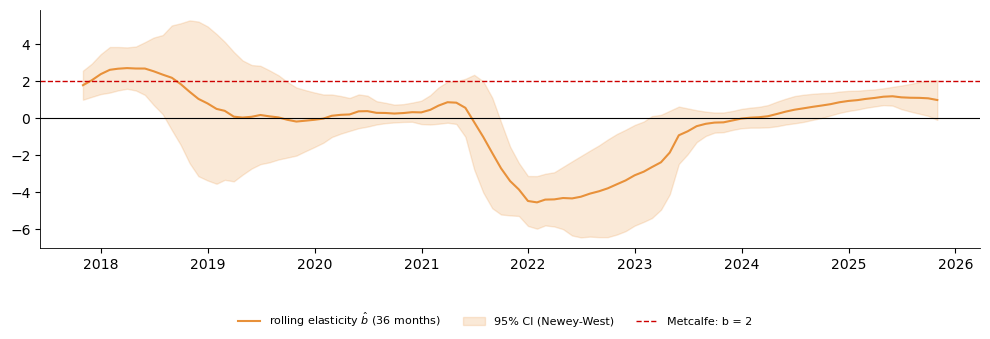

In [7]:
bs, ses, dts = [], [], []
for i in range(36, len(mm) + 1):
    s_ = mm.iloc[i - 36:i]
    r_ = sm.OLS(np.log(s_['mc']), sm.add_constant(np.log(s_['tx']))).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
    bs.append(r_.params.iloc[1]); ses.append(r_.bse.iloc[1]); dts.append(s_.index[-1])
bs, ses = np.array(bs), np.array(ses)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(dts, bs, color=BTC, label=r'rolling elasticity $\hat b$ (36 months)')
ax.fill_between(dts, bs - 1.96 * ses, bs + 1.96 * ses, color=BTC, alpha=0.2, label='95% CI (Newey-West)')
ax.axhline(2, color=RED, ls='--', lw=1, label='Metcalfe: b = 2')
ax.axhline(0, color='black', lw=0.8)
slide_legend(fig, 0.14, ncol=3)
save_fig(fig, 'ba_l2_metcalfe_rolling')

In [8]:
print(f'Windows: {len(bs)}; first ({dts[0]:%B %Y}): b = {bs[0]:.2f}; maximum {bs.max():.2f} (window ending '
      f'{dts[int(bs.argmax())]:%B %Y}); last ({dts[-1]:%B %Y}): {bs[-1]:.2f}')
neg = pd.Series(bs < 0, index=dts)
runs = (neg != neg.shift()).cumsum()[neg]                 # consecutive windows with a negative b
print(f'Windows with a negative b: {int(neg.sum())}, in {runs.nunique()} spells (window ends): ' +
      '; '.join(f'{g.index[0]:%b %Y} - {g.index[-1]:%b %Y}' for _, g in runs.groupby(runs)))
print(f'Share of windows whose 95% interval covers 2: {100 * np.mean((bs - 1.96 * ses <= 2) & (bs + 1.96 * ses >= 2)):.0f}%')

Windows: 97; first (October 2017): b = 1.78; maximum 2.70 (window ending March 2018); last (October 2025): 0.98
Windows with a negative b: 36, in 2 spells (window ends): Sep 2019 - Jan 2020; Jun 2021 - Dec 2023
Share of windows whose 95% interval covers 2: 28%
